In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones medias (en días) se adjunta. Para entender el método de Monte Carlo se han generado a mano sólo 5 réplicas de las duraciones (cada columna es una réplica: la duración que cada actividad ha tenido en esa simulación).

In [3]:
#| tbl-cap: "Cuadro de prelaciones y duraciones medias"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 8       ),
    ('B'     , '---'      , 7       ),
    ('C'     , 'A,B'      , 7       ),
    ('D'     , 'C'        , 8       ),
    ('E'     , 'B'        , 7       ),
    ('F'     , 'D,E'      , 5       ),
    ('G'     , 'D'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,8
B,---,7
C,"A,B",7
D,C,8
E,B,7
F,"D,E",5
G,D,6


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [4]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores


In [5]:
#| tbl-cap: "Duraciones simuladas (una columna por réplica)"
#| label: tbl-replicas
replicas = pd.DataFrame([
#  activity, r1, r2, r3, r4, r5
    ('A'     , 7 , 9 , 7 , 8 , 9 ),
    ('B'     , 8 , 6 , 6 , 6 , 7 ),
    ('C'     , 8 , 7 , 7 , 8 , 7 ),
    ('D'     , 8 , 8 , 7 , 8 , 9 ),
    ('E'     , 8 , 7 , 7 , 7 , 7 ),
    ('F'     , 5 , 4 , 4 , 4 , 6 ),
    ('G'     , 6 , 5 , 5 , 7 , 5 ),
], columns=['activity', 'r1', 'r2', 'r3', 'r4', 'r5']).set_index('activity')
replicas

,r1,r2,r3,r4,r5
activity,,,,,
A,7,9,7,8,9
B,8,6,6,6,7
C,8,7,7,8,7
D,8,8,7,8,9
E,8,7,7,7,7
F,5,4,4,4,6
G,6,5,5,7,5


In [6]:
pregunta_1 = "1. Dibuje el grafo PERT, enumere las rutas y escriba la matriz de rutas R (una fila por ruta, una columna por actividad).  "
pregunta_2 = "2. Escriba la matriz de tiempos T con las réplicas como columnas y calcule a mano el producto R·T. ¿Qué es cada elemento del resultado?  "
pregunta_3 = "3. Obtenga la duración del proyecto en cada réplica como el máximo de cada columna (τ = ‖R·t‖∞ para cada columna t). Calcule la media y la desviación típica muestral de las cinco duraciones.  "
pregunta_4 = "4. Para cada réplica, ¿qué ruta ha sido la crítica? Calcule el índice de criticidad de cada ruta y de cada actividad con estas cinco réplicas. Compare con el camino crítico de las duraciones medias.  "
pregunta_5 = "5. ¿Qué cambia al pasar de 5 réplicas a 10 000? Compruébelo generando las réplicas con una distribución normal de media la duración media y desviación típica 1.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT, enumere las rutas y escriba la matriz de rutas R (una fila por ruta, una columna por actividad).  

2. Escriba la matriz de tiempos T con las réplicas como columnas y calcule a mano el producto R·T. ¿Qué es cada elemento del resultado?  

3. Obtenga la duración del proyecto en cada réplica como el máximo de cada columna (τ = ‖R·t‖∞ para cada columna t). Calcule la media y la desviación típica muestral de las cinco duraciones.  

4. Para cada réplica, ¿qué ruta ha sido la crítica? Calcule el índice de criticidad de cada ruta y de cada actividad con estas cinco réplicas. Compare con el camino crítico de las duraciones medias.  

5. ¿Qué cambia al pasar de 5 réplicas a 10 000? Compruébelo generando las réplicas con una distribución normal de media la duración media y desviación típica 1.  

# Resolución

In [7]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT, enumere las rutas y escriba la matriz de rutas R (una fila por ruta, una columna por actividad).  

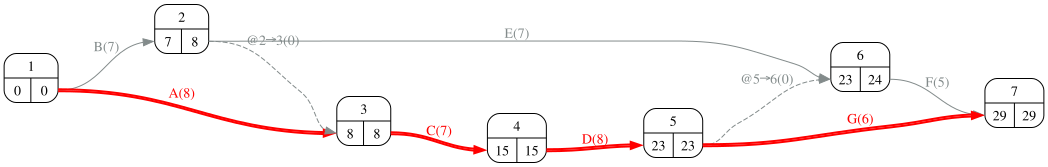

In [10]:
#| fig-cap: "Grafo PERT con las duraciones medias"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [11]:
#| tbl-cap: "Matriz de rutas R"
#| label: tbl-matrizRutas
R = proyecto.path_matrix(dummies=False)
rutas = proyecto.paths(dummies=False)
proyecto.display_path_matrix(dummies=False)

,A,B,C,D,E,F,G
Route_1,1,0,1,1,0,1,0
Route_2,1,0,1,1,0,0,1
Route_3,0,1,1,1,0,1,0
Route_4,0,1,1,1,0,0,1
Route_5,0,1,0,0,1,1,0


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Escriba la matriz de tiempos T con las réplicas como columnas y calcule a mano el producto R·T. ¿Qué es cada elemento del resultado?  

In [13]:
T = replicas.loc[R.columns]
RT = R @ T
Math(bmatrix(R) + r' \times ' + bmatrix(T) + ' = ' + bmatrix(RT))

<IPython.core.display.Math object>

In [14]:
#| tbl-cap: "R·T: duración de cada ruta (filas) en cada réplica (columnas)"
#| label: tbl-RT
RT

,r1,r2,r3,r4,r5
Route_1,28,28,25,28,31
Route_2,29,29,26,31,30
Route_3,29,25,24,26,29
Route_4,30,26,25,29,28
Route_5,21,17,17,17,20


El elemento (r, j) de R·T es la duración de la ruta r en la réplica j: la suma de las duraciones, en esa réplica, de las actividades que forman la ruta. Una fila de R selecciona las actividades de la ruta; una columna de T es un escenario completo.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Obtenga la duración del proyecto en cada réplica como el máximo de cada columna (τ = ‖R·t‖∞ para cada columna t). Calcule la media y la desviación típica muestral de las cinco duraciones.  

In [16]:
tau = RT.max()
pd.DataFrame({'τ = máximo de la columna': tau, 'ruta más larga': RT.idxmax()}).T

,r1,r2,r3,r4,r5
τ = máximo de la columna,30,29,26,31,31
ruta más larga,Route_4,Route_2,Route_2,Route_2,Route_1


In [17]:
media = tau.mean(); desviacion = tau.std(ddof=1)
Markdown(f'''Media = ({" + ".join(str(int(x)) for x in tau)}) / {len(tau)} = {media:.2f} días. Desviación típica muestral = √(Σ(τ − media)² / (n − 1)) = {desviacion:.2f} días. Con las duraciones medias el proyecto duraría {proyecto.duration(datos_proyecto["duration"])} días.''')

Media = (30 + 29 + 26 + 31 + 31) / 5 = 29.40 días. Desviación típica muestral = √(Σ(τ − media)² / (n − 1)) = 2.07 días. Con las duraciones medias el proyecto duraría 29 días.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Para cada réplica, ¿qué ruta ha sido la crítica? Calcule el índice de criticidad de cada ruta y de cada actividad con estas cinco réplicas. Compare con el camino crítico de las duraciones medias.  

In [19]:
ruta_critica = RT.idxmax()
criticidad_rutas = ruta_critica.value_counts().reindex(R.index, fill_value=0)
criticidad_actividades = R.loc[ruta_critica].sum()
pd.DataFrame({'actividades': [' - '.join(R.columns[R.loc[r] == 1]) for r in R.index],
              'veces crítica': criticidad_rutas, 'índice de criticidad': criticidad_rutas / len(tau)}, index=R.index)

,actividades,veces crítica,índice de criticidad
Route_1,A - C - D - F,1,0.2
Route_2,A - C - D - G,3,0.6
Route_3,B - C - D - F,0,0.0
Route_4,B - C - D - G,1,0.2
Route_5,B - E - F,0,0.0


In [20]:
pd.DataFrame({'veces en la ruta crítica': criticidad_actividades, 'índice de criticidad': criticidad_actividades / len(tau)}).T

,A,B,C,D,E,F,G
veces en la ruta crítica,4.0,1.0,5.0,5.0,0.0,1.0,4.0
índice de criticidad,0.8,0.2,1.0,1.0,0.0,0.2,0.8


In [21]:
camino_medio = proyecto.critical_path(datos_proyecto['duration'])
Markdown(f'Con las duraciones medias la ruta crítica es {", ".join(" - ".join(a) for a in camino_medio.values())}; en las réplicas ha sido la más larga '
         f'{int(criticidad_rutas.max())} de {len(tau)} veces. Con tan pocas réplicas los índices sólo pueden valer múltiplos de {1/len(tau):.1f}.')

Con las duraciones medias la ruta crítica es A - C - D - G; en las réplicas ha sido la más larga 3 de 5 veces. Con tan pocas réplicas los índices sólo pueden valer múltiplos de 0.2.

## Apartado 5

In [22]:
display(Markdown(pregunta_5))

5. ¿Qué cambia al pasar de 5 réplicas a 10 000? Compruébelo generando las réplicas con una distribución normal de media la duración media y desviación típica 1.  

In [23]:
rng = np.random.default_rng(1)
N = 10000
T_grande = pd.DataFrame(np.clip(rng.normal(datos_proyecto.loc[R.columns, 'duration'].values[:, None], 1.0, (len(R.columns), N)), 0.5, None), index=R.columns)
tau_grande = (R @ T_grande).max()
criticidad_grande = R.loc[(R @ T_grande).idxmax()].mean()
pd.DataFrame({'5 réplicas': [media, desviacion], '10 000 réplicas': [tau_grande.mean(), tau_grande.std(ddof=1)]}, index=['media', 'desviación típica']).round(2)

,5 réplicas,10 000 réplicas
media,29.40,29.36
desviación típica,2.07,1.88


In [24]:
pd.DataFrame({'5 réplicas': criticidad_actividades / len(tau), '10 000 réplicas': criticidad_grande}).round(3).T

,A,B,C,D,E,F,G
5 réplicas,0.800,0.200,1.0,1.0,0.0,0.200,0.800
10 000 réplicas,0.768,0.232,1.0,1.0,0.0,0.234,0.766


La operación es exactamente la misma (R·T y máximo por columnas); sólo cambia el número de columnas. Con muchas réplicas la media y la desviación típica se estabilizan (su error estadístico decrece como 1/√N) y los índices de criticidad dejan de ser múltiplos gruesos.